# PROJECT UTS PEMBELAJARAN MESIN 2026
# NAMA  : MOH. SYARIFUL AMAR
# NIM   : 202531001
# KELAS : H
# DOSEN : Rizqia Cahyaningtyas, ST., M.Kom
# DATASET: 04_bank_customers.csv (Dataset 4)
# ALGORITMA: Naive Bayes - Regresi Linear

In [2]:
# [CELL 1]: IMPORT LIBRARY UTAMA
# NIM: 202531001
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    mean_squared_error, r2_score
)

import warnings
warnings.filterwarnings('ignore')

In [4]:
# CELL 2: Load Dataset
# NIM: 202531001
df = pd.read_csv('04_bank_customers.csv', sep=';')
print("Dimensi Data:", df.shape)
df.head()

Dimensi Data: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [6]:
# CELL 3: Exploratory Data Analysis (EDA) - Ringkasan & Info Data
# NIM: 202531001
print("--- Informasi Dataset ---")
print(df.info())
print("\n--- Deskripsi Statistik (Numerik) ---")
print(df.describe())
print("\n--- Cek Missing Value ---")
print(df.isnull().sum())

--- Informasi Dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB
None

--- Deskripsi Statistik (Numerik) ---
                age        ba

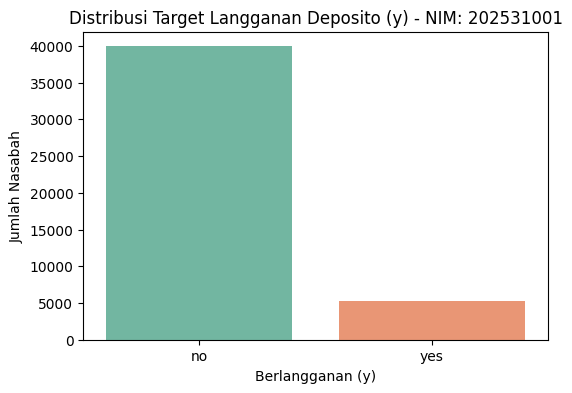

In [7]:
# CELL 4: Visualisasi Distribusi Target Langganan Deposito (y)
# NIM: 202531001
plt.figure(figsize=(6, 4))
sns.countplot(x='y', data=df, palette='Set2')
plt.title("Distribusi Target Langganan Deposito (y) - NIM: 202531001")
plt.xlabel("Berlangganan (y)")
plt.ylabel("Jumlah Nasabah")
plt.show()

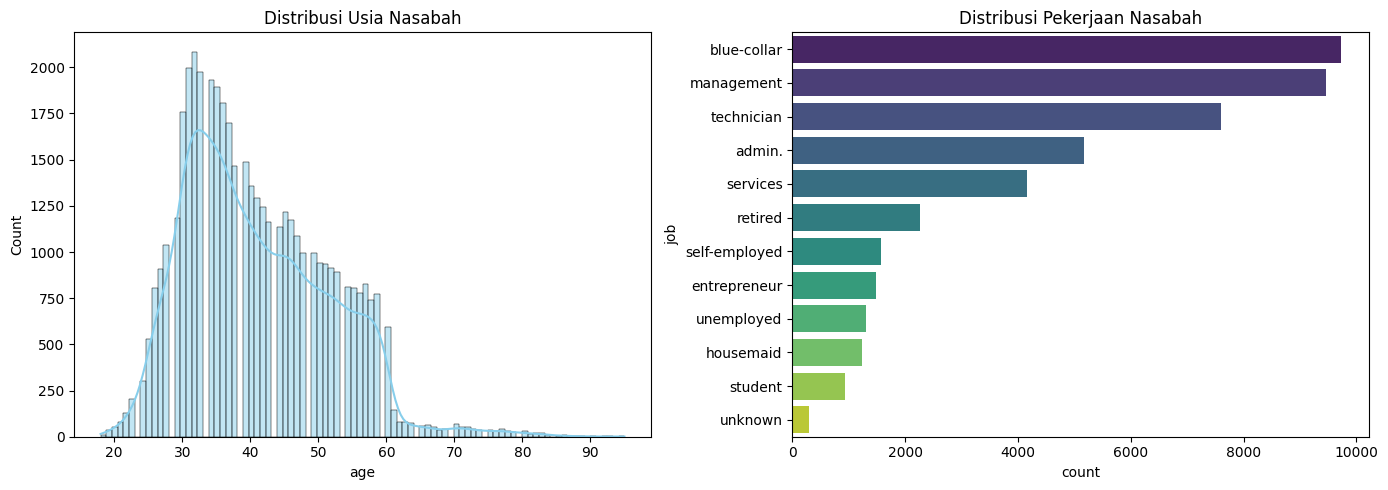

In [8]:
# CELL 5: Visualisasi Distribusi Usia dan Pekerjaan
# NIM: 202531001
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['age'], kde=True, ax=axes[0], color='skyblue')
axes[0].set_title("Distribusi Usia Nasabah")

sns.countplot(y='job', data=df, ax=axes[1], order=df['job'].value_counts().index, palette='viridis')
axes[1].set_title("Distribusi Pekerjaan Nasabah")
plt.tight_layout()
plt.show()

In [9]:
# CELL 6: Preprocessing Data - Label Encoding Variabel Kategorikal
# NIM: 202531001
df_encoded = df.copy()
label_encoders = {}
categorical_cols = df_encoded.select_dtypes(include=['object']).columns

for col in categorical_cols:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_encoded[col])
    label_encoders[col] = le

print("Data setelah Label Encoding (5 baris pertama):")
df_encoded.head()

Data setelah Label Encoding (5 baris pertama):


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,4,1,2,0,2143,1,0,2,5,8,261,1,-1,0,3,0
1,44,9,2,1,0,29,1,0,2,5,8,151,1,-1,0,3,0
2,33,2,1,1,0,2,1,1,2,5,8,76,1,-1,0,3,0
3,47,1,1,3,0,1506,1,0,2,5,8,92,1,-1,0,3,0
4,33,11,2,3,0,1,0,0,2,5,8,198,1,-1,0,3,0


In [10]:
# CELL 7: Pemodelan 1 - Naive Bayes (Klasifikasi Target: y)
# NIM: 202531001
X_clf = df_encoded.drop(columns=['y'])
y_clf = df_encoded['y']

# Train-Test Split (80% Train, 20% Test)
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)

nb_model = GaussianNB()
nb_model.fit(X_train_c, y_train_c)
y_pred_c = nb_model.predict(X_test_c)

=== EVALUASI MODEL NAIVE BAYES ===
Akurasi Naive Bayes: 84.45%

Classification Report:
              precision    recall  f1-score   support

          No       0.92      0.90      0.91      7985
         Yes       0.37      0.45      0.40      1058

    accuracy                           0.84      9043
   macro avg       0.65      0.67      0.66      9043
weighted avg       0.86      0.84      0.85      9043



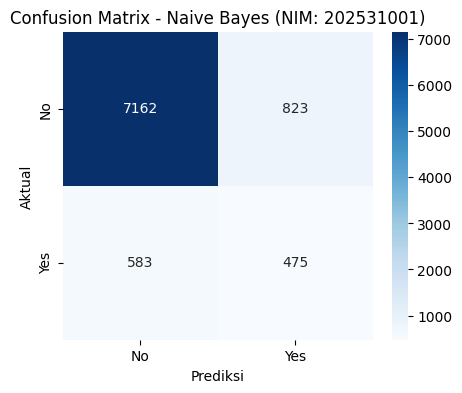

In [11]:
# CELL 8: Evaluasi Model 1 - Naive Bayes
# NIM: 202531001
acc_nb = accuracy_score(y_test_c, y_pred_c)
print(f"=== EVALUASI MODEL NAIVE BAYES ===")
print(f"Akurasi Naive Bayes: {acc_nb * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test_c, y_pred_c, target_names=['No', 'Yes']))

# Visualisasi Confusion Matrix
cm_nb = confusion_matrix(y_test_c, y_pred_c)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Blues', xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
plt.title("Confusion Matrix - Naive Bayes (NIM: 202531001)")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.show()

In [13]:
# CELL 9: Pemodelan 2 - Regresi Linear (Regresi Target: balance)
# NIM: 202531001
X_reg = df_encoded.drop(columns=['balance'])
y_reg = df_encoded['balance']

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

# Standard Scaling pada fitur numerik untuk Regresi Linear
scaler = StandardScaler()
X_train_r_scaled = scaler.fit_transform(X_train_r)
X_test_r_scaled = scaler.transform(X_test_r)

lr_model = LinearRegression()
lr_model.fit(X_train_r_scaled, y_train_r)
y_pred_r = lr_model.predict(X_test_r_scaled)

=== EVALUASI MODEL REGRESI LINEAR ===
Mean Squared Error (MSE)   : 9510128.5925
Root Mean Squared Error (RMSE): 3083.8496
R-squared (R2 Score)       : 0.0293


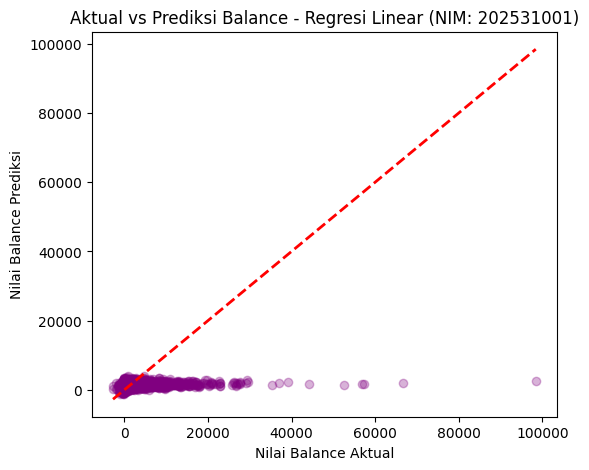

In [14]:
# CELL 10: Evaluasi Model 2 - Regresi Linear
# NIM: 202531001
mse_lr = mean_squared_error(y_test_r, y_pred_r)
rmse_lr = np.sqrt(mse_lr)
r2_lr = r2_score(y_test_r, y_pred_r)

print(f"=== EVALUASI MODEL REGRESI LINEAR ===")
print(f"Mean Squared Error (MSE)   : {mse_lr:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse_lr:.4f}")
print(f"R-squared (R2 Score)       : {r2_lr:.4f}")

# Visualisasi Prediksi vs Nilai Aktual
plt.figure(figsize=(6, 5))
plt.scatter(y_test_r, y_pred_r, alpha=0.3, color='purple')
plt.plot([y_test_r.min(), y_test_r.max()], [y_test_r.min(), y_test_r.max()], 'r--', lw=2)
plt.title("Aktual vs Prediksi Balance - Regresi Linear (NIM: 202531001)")
plt.xlabel("Nilai Balance Aktual")
plt.ylabel("Nilai Balance Prediksi")
plt.show()